In [1]:
import numpy as np
import os
import soundfile as sf 
import librosa
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [2]:
# Function that finds all files with a certain extension in a particular folder
def find_all_files(folders, ext, check_sub_folders=1):
    """Find all files with a .txt extension in all folders in folder list (and subfolders if check_sub_folders = 1 (default))"""
    all_files = []
    if isinstance(folders, str):
        # Make sure input is a list of folders
        folders = [folders]
    for f, folder in enumerate(folders):
        for subfolder in os.listdir(folder):

            if os.path.isdir(os.path.join(folder, subfolder)):
                if check_sub_folders:
                    folders.append(os.path.join(folder, subfolder))                
            elif subfolder.endswith(ext):
                all_files.append(os.path.join(folder,subfolder))
    return all_files

In [3]:
# Function that pads or cuts a spectrogram to a certain size, adapted from avgn
def pad_spectrogram(spectrogram, pad_length):
    """ Pads a spectrogram to being a certain length
    """
    excess_needed = pad_length - np.shape(spectrogram)[1]
    pad_left = np.floor(float(excess_needed) / 2).astype("int")
    pad_right = np.ceil(float(excess_needed) / 2).astype("int")
    if excess_needed >= 0:
        return np.pad(
            spectrogram, [(0, 0), (pad_left, pad_right)], "constant", constant_values=0
        )
    else:
        pad_left = np.floor(float(excess_needed) / 2).astype("int")
        pad_right = np.ceil(float(excess_needed) / 2).astype("int")
        return spectrogram[:,-1*pad_left:pad_right]

## Setup

In [4]:
# Constant variables
fmin = 1000
fmax = 20000 # Max frequency cutoff
spec_shape = [128, 128] #Shape of spectrogram
n_fft = 2048
hop_length = int(n_fft/2)


In [5]:
# Find all the audio files
data_folder = r"test_data"
data_files = find_all_files(data_folder, '.flac')

For these methods, we ideally want all spectrograms to have the same dimensions (spec_shape). We will thus pad the spectrograms to add margins to the side.

In [6]:
## Example data file
file = data_files[500]
data, sr = sf.read(file) # read in the file using soundfile

# Calculate spectrograms
mel_spec = librosa.feature.melspectrogram(y=data, sr=sr, n_mels=128, n_fft=n_fft, hop_length = hop_length)
padded_spec = pad_spectrogram(mel_spec, spec_shape[1])
print(padded_spec.shape)

(128, 128)


Text(0.5, 1.0, 'Padded')

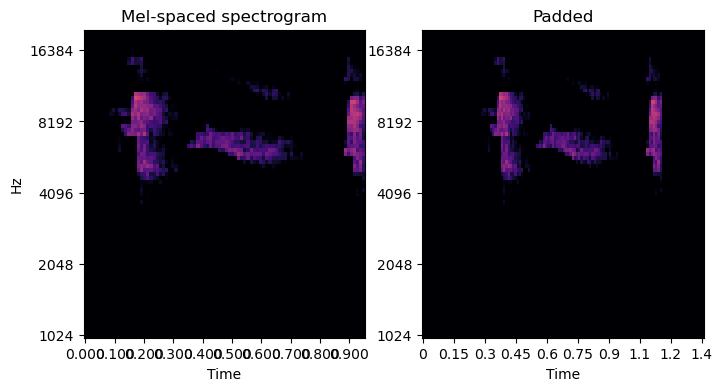

In [7]:
fig, ax = plt.subplots(ncols=2, sharex=False, figsize=(8, 4))
mel_img = librosa.display.specshow(mel_spec, x_axis='time', y_axis='mel',vscale="dBFS",sr=sr, ax=ax[0],  n_fft=n_fft, hop_length = hop_length)
ax[0].set_ylim((fmin, fmax))
ax[0].set_title('Mel-spaced spectrogram')

padded_img = librosa.display.specshow(padded_spec, x_axis='time', y_axis='mel',vscale="dBFS",sr=sr, ax=ax[1],  n_fft=n_fft, hop_length = hop_length)
ax[1].set_ylim((fmin, fmax))
ax[1].set_title('Padded')

# Preprocessing the data

We want to run through all the calls and extract spectrograms. In this case, the code below does, and saves it into a TF records format, which is a binary format (for more info see [here](https://www.tensorflow.org/tutorials/load_data/tfrecord). This is largely for practicality, as helps speed up the AE training. However, you can also put all the spectograms in an array or dataframe (though this will quickly fill up your memory if you have a lot of calls). The methods here were developed by Tim Sainburg and adapted from his [AVGN](https://github.com/timsainb/AVGN) package.

In [17]:
from avgn_utils import spec_to_record
import tensorflow as tf
n_records = 0
record_loc = r"marmoset_calls.tfrecords"
data_array = np.full((len(data_files), spec_shape[0]*spec_shape[1]), np.nan)
call_types = []
# Run through each audio file and extract the spectrograms
with tf.io.TFRecordWriter(record_loc) as writer:
    for i, file in enumerate(data_files):
        data, sr = sf.read(file) 
        call_type = os.path.basename(file).split('_')[0]
        call_id = os.path.splitext(os.path.basename(file))[0].split('_')[1]
        
        duration = len(data)/sr
    
        mel_spec = librosa.feature.melspectrogram(y=data, sr=sr, n_mels=128, n_fft=n_fft, hop_length = hop_length)
        padded_spec = pad_spectrogram(mel_spec, spec_shape[1])
    
        record = spec_to_record(padded_spec, call_id, call_type) 
        writer.write(record)
        n_records +=1

        data_array[i,:] = padded_spec.flatten()
        call_types += [call_type]
    print(n_records)

2020


## UMAP latent variables
We can UMAP (or other dimensionality reduction methods) to directly extract latent variables from the raw spectrograms. This works reasonably well, but may be sensitive to noise, especially when inputting high-dimensional spectrograms. 

In [16]:
import umap
reducer = umap.UMAP()
umap_results = reducer.fit_transform(data_array) # fit_transform fits the model and gives you the results


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\door1\miniforge3\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\door1\miniforge3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\door1\miniforge3\Lib\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io_loop.start()
  File "C:\Users\door1\miniforge3\Lib\site-

<Axes: xlabel='UMAP1', ylabel='UMAP2'>

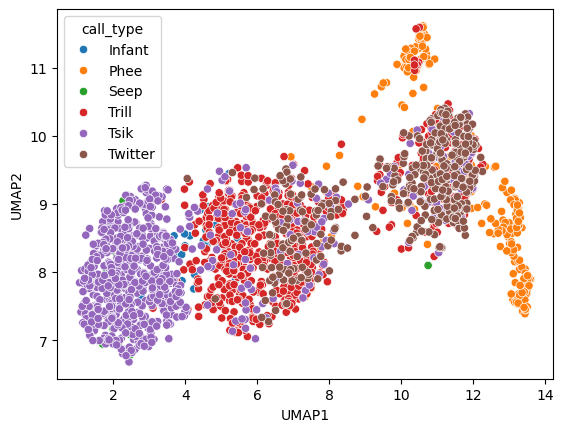

In [19]:
umap_results_df = pd.DataFrame(umap_results, columns=["UMAP1", "UMAP2"])
umap_results_df['call_type'] = call_types
sns.scatterplot(data=umap_results_df, x="UMAP1", y="UMAP2", hue="call_type")

Above, we extract just 2 variables for plotting but you can extract a larger number of UMAP features for further post-processing, for example clustering or classifiers.

In [23]:
n_dims = 32
reducer = umap.UMAP(n_components=n_dims)
umap_results = reducer.fit_transform(data_array) # fit_transform fits the model and gives you the results
umap_results_df = pd.DataFrame(umap_results, columns=['UMAP{}'.format(i+1) for i in range(n_dims)])
umap_results_df['call_type'] = call_types
umap_results_df.to_csv('umap_features.csv') # Save out the features to csv 